In [1]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load the Excel file
df = pd.read_excel("applications.xlsx")
# Preview the data
print(df.shape)
print(df.head())
# Check for missing values
print(df.isna().sum())

Matplotlib is building the font cache; this may take a moment.


(17339, 7)
   Applicant Sex  SAT_ACT               College Admitted Enrolled  \
0          1   M     1460  Business & Economics      Yes       No   
1          2   F     1180        Math & Science       No       No   
2          3   M     1340        Arts & Letters      Yes       No   
3          4   M     1190  Business & Economics       No       No   
4          5   F     1290  Business & Economics       No       No   

   Extracurricular_Hours  
0                      5  
1                     10  
2                      7  
3                      1  
4                      4  
Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64


College
Arts & Letters          6964
Business & Economics    4103
Math & Science          6272
Name: Applicant, dtype: int64


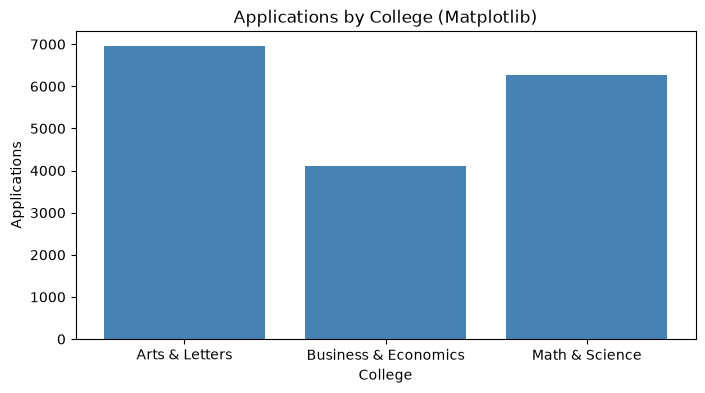

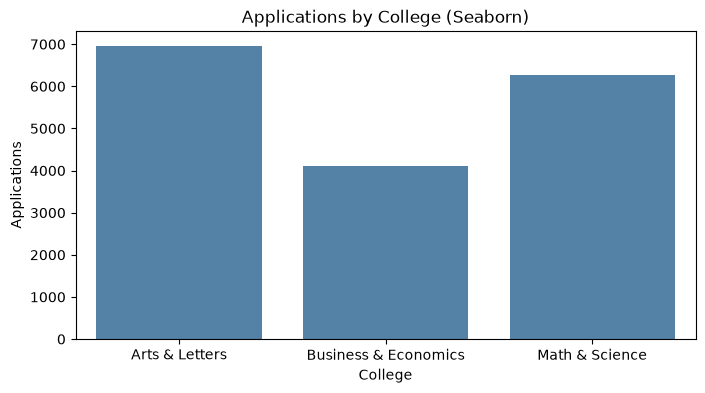

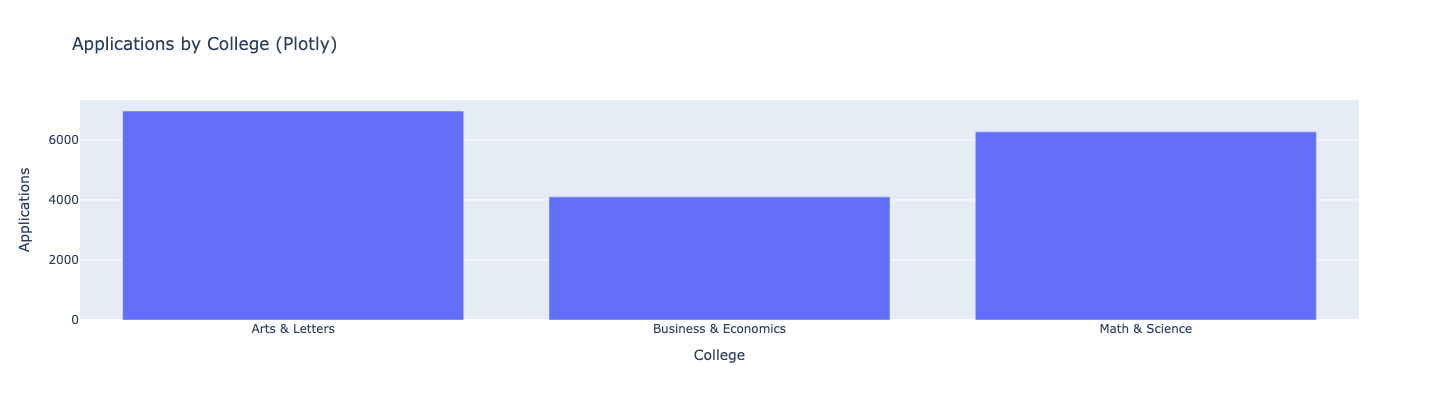

In [2]:
# Task 01: Applications by college
# Count applications by college
applications = df.groupby("College")["Applicant"].count()
print(applications)

# 1.1 Matplotlib bar chart
plt.figure(figsize=(8, 4))
plt.bar(applications.index, applications.values, color="steelblue")
plt.title("Applications by College (Matplotlib)")
plt.xlabel("College")
plt.ylabel("Applications")
plt.show()

# 1.2 Seaborn bar chart
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="College", order=applications.index, color="steelblue")
plt.title("Applications by College (Seaborn)")
plt.xlabel("College")
plt.ylabel("Applications")
plt.show()

# 1.3 Plotly bar chart
fig = px.bar(x=applications.index, y=applications.values,
             labels={"x": "College", "y": "Applications"},
             title="Applications by College (Plotly)", width=800, height=400)
fig.show()

200 to 299 : 1
300 to 399 : 5
400 to 499 : 1
500 to 599 : 15
600 to 699 : 57
700 to 799 : 276
800 to 899 : 785
900 to 999 : 1705
1000 to 1099 : 2928
1100 to 1199 : 3910
1200 to 1299 : 3717
1300 to 1399 : 2363
1400 to 1499 : 1204
1500 to 1599 : 364
1600 to 1699 : 8


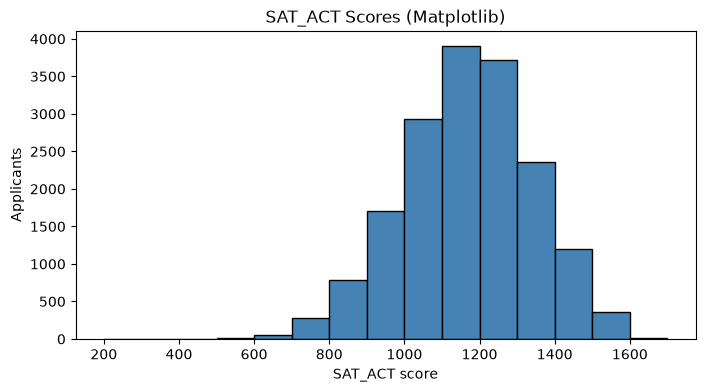

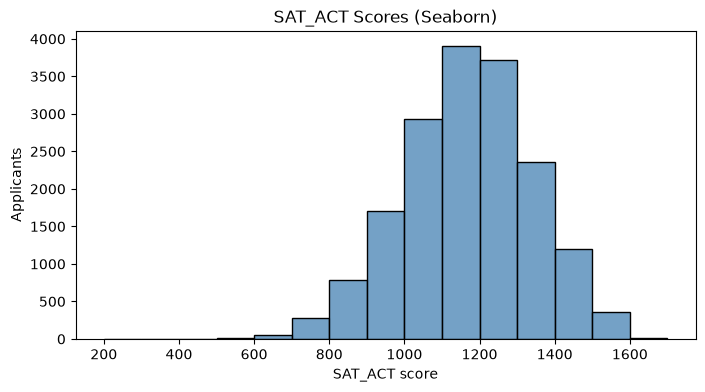

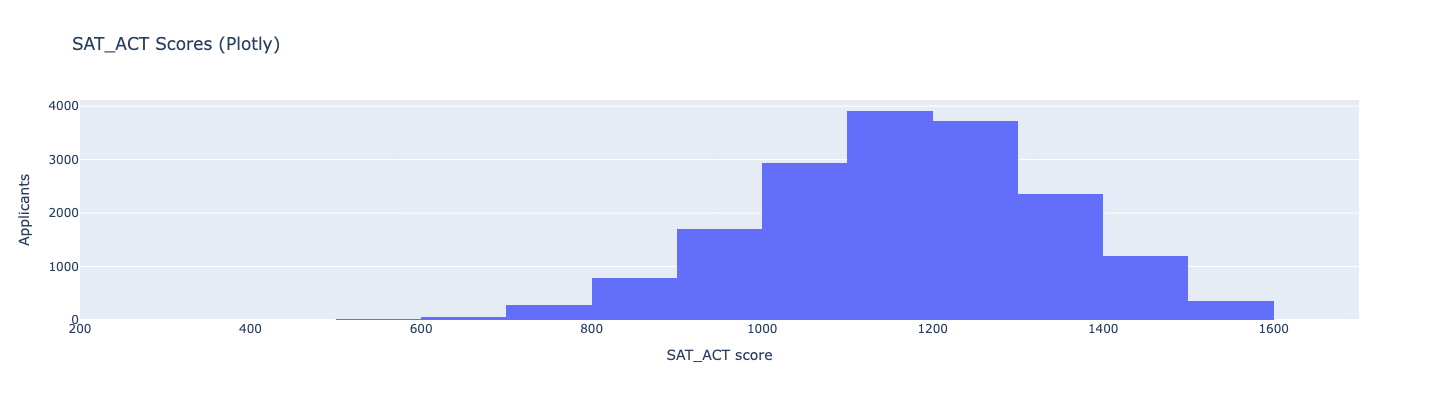

In [3]:
# Task 02: Distribution of SAT_ACT scores
# Select test scores
scores = df["SAT_ACT"]
# Set 100-point bins
first_score = scores.min() // 100 * 100
last_score = scores.max() // 100 * 100 + 100
bins = list(range(first_score, last_score + 1, 100))

# Count scores in each bin
for start in bins[:-1]:
    count = ((scores >= start) & (scores < start + 100)).sum()
    print(start, "to", start + 99, ":", count)

# 2.1 Matplotlib histogram
plt.figure(figsize=(8, 4))
plt.hist(scores, bins=bins, color="steelblue", edgecolor="black")
plt.title("SAT_ACT Scores (Matplotlib)")
plt.xlabel("SAT_ACT score")
plt.ylabel("Applicants")
plt.show()

# 2.2 Seaborn histogram
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="SAT_ACT", bins=bins, color="steelblue")
plt.title("SAT_ACT Scores (Seaborn)")
plt.xlabel("SAT_ACT score")
plt.ylabel("Applicants")
plt.show()

# 2.3 Plotly histogram
fig = px.histogram(df, x="SAT_ACT", title="SAT_ACT Scores (Plotly)",
                   labels={"SAT_ACT": "SAT_ACT score"}, width=800, height=400)
# Match the bin widths
fig.update_traces(xbins={"start": first_score, "end": last_score, "size": 100})
fig.update_yaxes(title_text="Applicants")
fig.show()

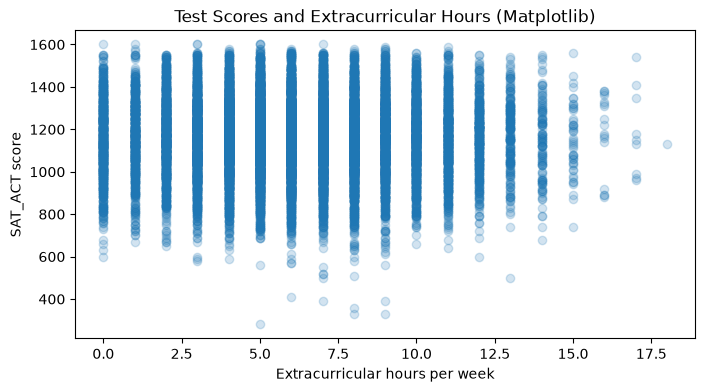

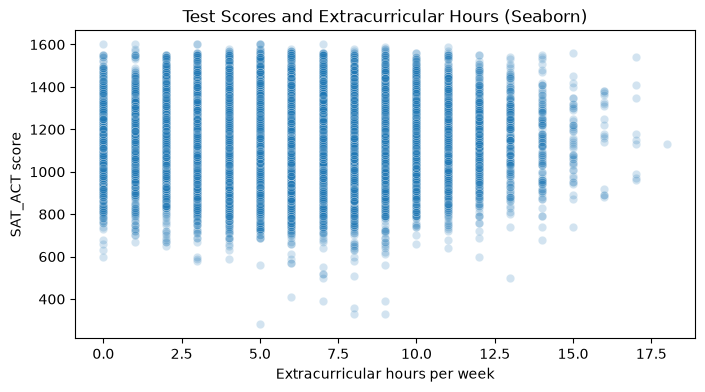

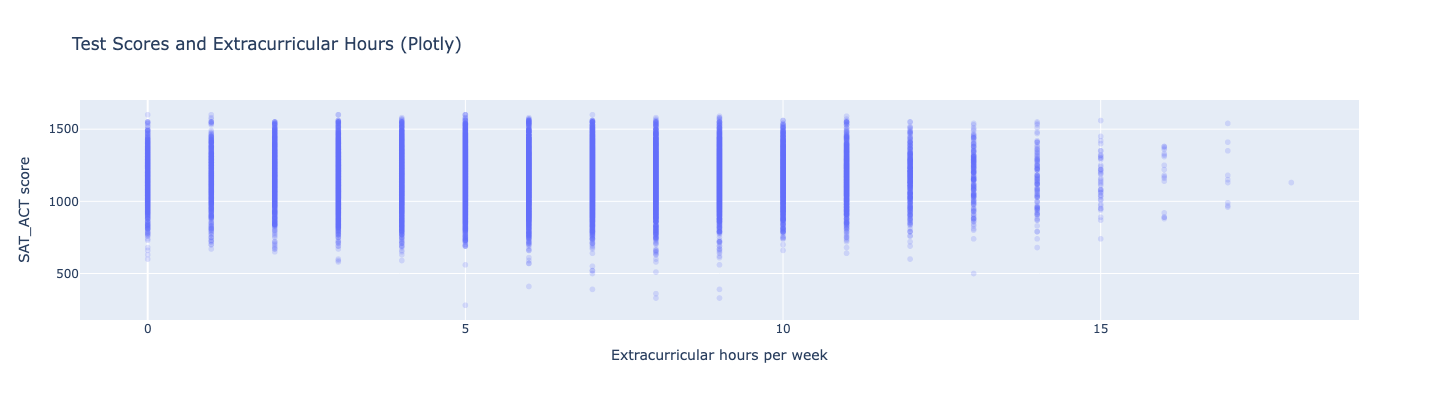

Extracurricular_Hours
0     1152.8
1     1161.7
2     1175.3
3     1160.4
4     1167.1
5     1168.6
6     1161.8
7     1164.4
8     1161.7
9     1165.8
10    1170.8
11    1159.8
12    1162.6
13    1175.4
14    1147.3
15    1151.5
16    1185.3
17    1186.7
18    1130.0
Name: SAT_ACT, dtype: float64


In [4]:
# Task 03: Test scores and extracurricular hours
# 3.1 Matplotlib scatter plot
plt.figure(figsize=(8, 4))
plt.scatter(df["Extracurricular_Hours"], df["SAT_ACT"], alpha=0.2)
plt.title("Test Scores and Extracurricular Hours (Matplotlib)")
plt.xlabel("Extracurricular hours per week")
plt.ylabel("SAT_ACT score")
plt.show()

# 3.2 Seaborn scatter plot
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x="Extracurricular_Hours", y="SAT_ACT", alpha=0.2)
plt.title("Test Scores and Extracurricular Hours (Seaborn)")
plt.xlabel("Extracurricular hours per week")
plt.ylabel("SAT_ACT score")
plt.show()

# 3.3 Plotly scatter plot
fig = px.scatter(df, x="Extracurricular_Hours", y="SAT_ACT", opacity=0.2,
                 labels={"Extracurricular_Hours": "Extracurricular hours per week",
                         "SAT_ACT": "SAT_ACT score"},
                 title="Test Scores and Extracurricular Hours (Plotly)",
                 width=800, height=400)
fig.show()

# Show average scores by hour
print(df.groupby("Extracurricular_Hours")["SAT_ACT"].mean().round(1))

## Task 04 · Findings and recommendations

1. **Arts & Letters received the most applications.** It received 6,964, followed by Math & Science with 6,272 and Business & Economics with 4,103. Schedule more application reviewers for Arts & Letters during peak weeks and use each college’s past enrollment yield to estimate how many admitted students will enroll.
2. **The most common SAT_ACT score range was 1,100–1,199.** That range included 3,910 applicants. Compare admit and enrollment rates across score ranges to see where admitted students might benefit from more follow-up.
3. **There was no clear relationship between test scores and extracurricular hours.** The points were spread out, and average scores did not steadily rise or fall as hours increased. Review extracurricular involvement separately when evaluating applicants and use past enrollment rates to plan for incoming class sizes.